# Week 3 (Part B) — Parameter-Efficient Fine-Tuning with QLoRA

## 1. Objective
This notebook adapts a pre-trained open-weight language model to a specific task with a parameter-efficient method, then compares the adapted model with the original on held-out examples.

## 2. Task and Link to Part A
**Task: closed-book-style question answering from a supplied context.** The model receives an instruction (a question) and an input passage, and must answer the question concisely from that passage. This is the generation step of the RAG pipeline in Part A. A model that reliably answers from the given context, stops when the answer is complete, and keeps to the point is a better RAG generator.

## 3. Design Choices

| Choice | Decision | Justification |
|---|---|---|
| Base model | `Qwen/Qwen2.5-0.5B` (base, not instruction-tuned), Apache 2.0 | A base model has never been taught to follow instructions, so the effect of fine-tuning is clearly visible. An instruct model has already been trained on similar data, which would hide the effect. At 0.5B parameters, training fits comfortably on a free T4 in minutes. |
| Method | QLoRA: 4-bit NF4 quantised base + LoRA adapters | The method used in the Week 3 lab; trains well under 1% of parameters. If 4-bit loading is unavailable, the notebook falls back to standard LoRA on a full-precision base. |
| Dataset | `databricks/databricks-dolly-15k`, `closed_qa` category | The lab's dataset; human-written, openly licensed (CC BY-SA 3.0); every example pairs a question with a reference passage, matching the RAG generation task |
| Split | 800 training, 20 held-out test examples, shuffled with seed 42 | Within the lab's 500–2,000 guidance; test examples are never seen in training |
| Prompt format | Alpaca-style `### Instruction / ### Input / ### Response` | The lab's format; the same template is used for training and testing |
| Loss masking | Loss computed on response tokens only | The model learns to *answer*, not to reproduce the question and passage |

## 4. Environment Setup

In [1]:
!pip install -q peft datasets bitsandbytes

import os, re, time, json, platform, warnings
warnings.filterwarnings("ignore")
import torch, transformers, peft
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer, TrainingArguments, Trainer
from peft import LoraConfig, get_peft_model, TaskType

os.makedirs("outputs", exist_ok=True)
pd.set_option("display.max_colwidth", 200)
print("Python:", platform.python_version(), "| PyTorch:", torch.__version__,
      "| transformers:", transformers.__version__, "| peft:", peft.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

Python: 3.13.16 | PyTorch: 2.14.1+cu130 | transformers: 5.22.1 | peft: 0.21.2
GPU: Tesla T4


## 5. Helper Functions
Prompt formatting, tokenisation with loss masking, batch padding and evaluation metrics.

In [2]:
PROMPT_WITH_CONTEXT = "### Instruction:\n{instruction}\n\n### Input:\n{context}\n\n### Response:\n"
PROMPT_NO_CONTEXT = "### Instruction:\n{instruction}\n\n### Response:\n"


def build_prompt(example):
    if example.get("context"):
        return PROMPT_WITH_CONTEXT.format(instruction=example["instruction"].strip(), context=example["context"].strip())
    return PROMPT_NO_CONTEXT.format(instruction=example["instruction"].strip())


def tokenize_example(example, tokenizer, max_length=512):
    """Tokenise prompt + response. Prompt tokens get label -100 so the loss is computed on the response only."""
    prompt_ids = tokenizer(build_prompt(example), add_special_tokens=False)["input_ids"]
    response_ids = tokenizer(example["response"].strip(), add_special_tokens=False)["input_ids"] + [tokenizer.eos_token_id]
    input_ids = (prompt_ids + response_ids)[:max_length]
    labels = ([-100] * len(prompt_ids) + response_ids)[:max_length]
    return {"input_ids": input_ids, "attention_mask": [1] * len(input_ids), "labels": labels}


class PadCollator:
    def __init__(self, pad_id):
        self.pad_id = pad_id

    def __call__(self, batch):
        width = max(len(b["input_ids"]) for b in batch)
        pad = lambda seq, value: seq + [value] * (width - len(seq))
        return {
            "input_ids": torch.tensor([pad(b["input_ids"], self.pad_id) for b in batch]),
            "attention_mask": torch.tensor([pad(b["attention_mask"], 0) for b in batch]),
            "labels": torch.tensor([pad(b["labels"], -100) for b in batch]),
        }


def _tokens(text):
    return re.findall(r"[a-z0-9]+", text.lower())


def rouge_l(prediction, reference):
    """ROUGE-L F1 based on the longest common subsequence of word tokens."""
    p, r = _tokens(prediction), _tokens(reference)
    if not p or not r:
        return 0.0
    dp = [[0] * (len(r) + 1) for _ in range(len(p) + 1)]
    for i in range(len(p)):
        for j in range(len(r)):
            dp[i + 1][j + 1] = dp[i][j] + 1 if p[i] == r[j] else max(dp[i][j + 1], dp[i + 1][j])
    lcs = dp[-1][-1]
    if lcs == 0:
        return 0.0
    precision, recall = lcs / len(p), lcs / len(r)
    return 2 * precision * recall / (precision + recall)


def clean_answer(raw):
    """Cut the answer where the model starts a new prompt section."""
    return re.split(r"\n\s*###|\n\s*Instruction:", raw)[0].strip()


def runaway(raw):
    """True if the model kept going past its answer and started writing new prompt sections."""
    return bool(re.search(r"###\s*(Instruction|Input|Response)", raw))

## 6. Dataset Preparation
The `closed_qa` subset is filtered to examples whose full prompt and response fit within 512 tokens, so no example is truncated during training. A few formatted examples are printed for a manual check before training, as the lab recommends.

In [3]:
MODEL_ID = "Qwen/Qwen2.5-0.5B"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

raw = load_dataset("databricks/databricks-dolly-15k", split="train")
closed_qa = raw.filter(lambda x: x["category"] == "closed_qa")
fits = closed_qa.filter(lambda x: len(tokenizer(build_prompt(x) + x["response"])["input_ids"]) < 510)
shuffled = fits.shuffle(seed=42)
train_raw = shuffled.select(range(800))
test_raw = shuffled.select(range(800, 820))

print(f"Dolly-15k: {len(raw)} examples | closed_qa: {len(closed_qa)} | fit in 512 tokens: {len(fits)}")
print(f"Training: {len(train_raw)} | Held-out test: {len(test_raw)}")
lengths = [len(tokenizer(build_prompt(x) + x["response"])["input_ids"]) for x in train_raw]
print(f"Training example length: mean {sum(lengths)/len(lengths):.0f} tokens, max {max(lengths)}")

print("\n===== Formatted training example =====")
print(build_prompt(train_raw[0]) + train_raw[0]["response"])

train_tok = train_raw.map(lambda e: tokenize_example(e, tokenizer), remove_columns=train_raw.column_names)
masked = sum(l == -100 for l in train_tok[0]["labels"])
print(f"\nExample 0: {len(train_tok[0]['input_ids'])} tokens, {masked} prompt tokens masked from the loss")

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

README.md:   0%|          | 0.00/8.20k [00:00<?, ?B/s]

... (4 outputs left out)

Filter:   0%|          | 0/1773 [00:00<?, ? examples/s]

Dolly-15k: 15011 examples | closed_qa: 1773 | fit in 512 tokens: 1569
Training: 800 | Held-out test: 20
Training example length: mean 237 tokens, max 507

===== Formatted training example =====
### Instruction:
According to this paragraph about bull sharks, how long are male adult sharks in meters?

### Input:
Bull sharks are large and stout, with females being larger than males. The bull shark can be up to 81 cm (2 ft 8 in) in length at birth. Adult female bull sharks average 2.4 m (8 ft) long and typically weigh 130 kg (290 lb), whereas the slightly smaller adult male averages 2.25 m (7 ft) and 95 kg (209 lb). While a maximum size of 3.5 m (11 ft) is commonly reported, a single record exists of a female specimen of exactly 4.0 m (13 ft). A 3.25 m (10.7 ft) long pregnant individual reached 450 kg (990 lb). Bull sharks are wider and heavier than other requiem sharks of comparable length, and are grey on top and white below. The second dorsal fin is smaller than the first. The bull shar

Map:   0%|          | 0/800 [00:00<?, ? examples/s]


Example 0: 274 tokens, 259 prompt tokens masked from the loss


## 7. Loading the Base Model in 4-bit and Attaching LoRA Adapters

| LoRA setting | Value | Meaning |
|---|---|---|
| r (rank) | 16 | Size of the low-rank update matrices |
| lora_alpha | 32 | Scaling of the update (2 × r, the common heuristic) |
| target_modules | q_proj, k_proj, v_proj, o_proj | The attention projections, the most effective targets for instruction tuning |
| lora_dropout | 0.05 | Regularisation on the adapter |
| Quantisation | 4-bit NF4, double quantisation, float32 compute | float32 compute avoids fp16 overflow on the T4, which does not support bfloat16 |

In [4]:
try:
    from transformers import BitsAndBytesConfig
    from peft import prepare_model_for_kbit_training
    bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                    bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float32)
    base_model = AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=bnb_config, device_map="cuda")
    base_model = prepare_model_for_kbit_training(base_model)
    METHOD = "QLoRA (4-bit NF4 base model)"
except Exception as err:
    print("4-bit loading unavailable, using standard LoRA instead:", err)
    base_model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float32, device_map="cuda")
    base_model.gradient_checkpointing_enable()
    base_model.enable_input_require_grads()
    METHOD = "LoRA (full-precision base model)"

base_model.config.use_cache = False
print("Method:", METHOD)
print(f"Base model memory: {base_model.get_memory_footprint() / 1e9:.2f} GB")

lora_config = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, bias="none", task_type=TaskType.CAUSAL_LM,
                         target_modules=["q_proj", "k_proj", "v_proj", "o_proj"])
model = get_peft_model(base_model, lora_config)
model.print_trainable_parameters()

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

Method: QLoRA (4-bit NF4 base model)
Base model memory: 0.72 GB
trainable params: 2,162,688 || all params: 496,195,456 || trainable%: 0.4359


## 8. Training

| Setting | Value |
|---|---|
| Epochs | 2 |
| Per-device batch size | 4 |
| Gradient accumulation | 2 (effective batch size 8) |
| Learning rate | 2e-4, cosine schedule, 20 warm-up steps |
| Optimiser | AdamW (Trainer default) |
| Total optimisation steps | 200 |

Step,Training Loss
10,1.137457
20,1.062787
30,1.175499
40,0.877288
50,1.252364
60,1.143681
70,0.939846
80,1.104227
90,0.978260
100,1.085560


Training time: 10.4 min | final training loss: 1.013


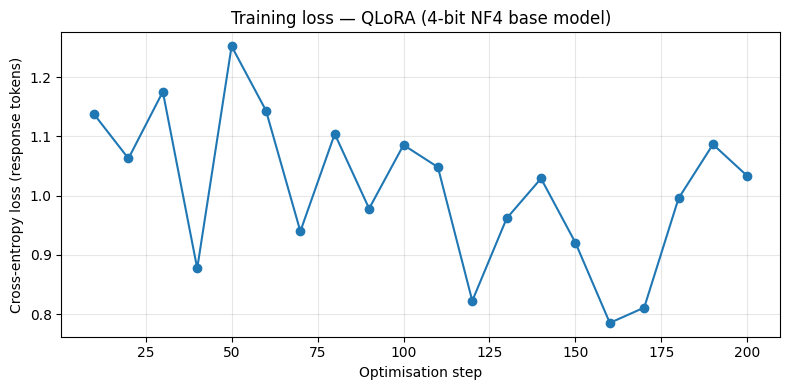

Adapter saved to outputs/lora-adapter (8.7 MB)


In [5]:
args = TrainingArguments(
    output_dir="outputs/qlora-checkpoints",
    num_train_epochs=2,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=2,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=20,
    logging_steps=10,
    save_strategy="no",
    report_to="none",
    remove_unused_columns=False,
    seed=42,
)
trainer = Trainer(model=model, args=args, train_dataset=train_tok,
                  data_collator=PadCollator(tokenizer.pad_token_id))

start = time.time()
train_result = trainer.train()
train_minutes = (time.time() - start) / 60
print(f"Training time: {train_minutes:.1f} min | final training loss: {train_result.training_loss:.3f}")

log = pd.DataFrame([h for h in trainer.state.log_history if "loss" in h])
plt.figure(figsize=(8, 4))
plt.plot(log["step"], log["loss"], marker="o")
plt.title(f"Training loss — {METHOD}")
plt.xlabel("Optimisation step")
plt.ylabel("Cross-entropy loss (response tokens)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("outputs/training_loss.png", dpi=120)
plt.show()

model.save_pretrained("outputs/lora-adapter")
tokenizer.save_pretrained("outputs/lora-adapter")
adapter_mb = sum(os.path.getsize(os.path.join("outputs/lora-adapter", f))
                 for f in os.listdir("outputs/lora-adapter") if f.endswith(".safetensors")) / 1e6
print(f"Adapter saved to outputs/lora-adapter ({adapter_mb:.1f} MB)")

## 9. Evaluation: Base Model versus Fine-Tuned Model
Both models answer the same 20 held-out questions with greedy decoding, a 128-token limit and a repetition penalty of 1.1. The base model is the same network with the LoRA adapter switched off, so the only difference between the two is the adapter.

**Metrics**
- **ROUGE-L F1** against the human reference answer, computed on the answer text before any new `###` section.
- **Runaway rate:** share of outputs where the model keeps generating new `### Instruction` / `### Response` blocks after its answer, a format failure.
- **Answer length** in words.
- **Human review:** each pair is printed in Section 9.2 and scored 1–5 on relevance, correctness and format adherence, following the lab.

In [6]:
model.config.use_cache = True
model.eval()

def generate_answer(example, use_adapter=True, max_new_tokens=128):
    inputs = tokenizer(build_prompt(example), return_tensors="pt").to("cuda")
    settings = dict(max_new_tokens=max_new_tokens, do_sample=False, repetition_penalty=1.1,
                    pad_token_id=tokenizer.pad_token_id)
    with torch.no_grad():
        if use_adapter:
            out = model.generate(**inputs, **settings)
        else:
            with model.disable_adapter():
                out = model.generate(**inputs, **settings)
    return tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)

rows = []
for i, ex in enumerate(test_raw):
    base_raw = generate_answer(ex, use_adapter=False)
    ft_raw = generate_answer(ex, use_adapter=True)
    rows.append({
        "id": i, "question": ex["instruction"], "reference": ex["response"],
        "base_answer": clean_answer(base_raw), "ft_answer": clean_answer(ft_raw),
        "base_rougeL": rouge_l(clean_answer(base_raw), ex["response"]),
        "ft_rougeL": rouge_l(clean_answer(ft_raw), ex["response"]),
        "base_runaway": runaway(base_raw), "ft_runaway": runaway(ft_raw),
        "base_words": len(clean_answer(base_raw).split()), "ft_words": len(clean_answer(ft_raw).split()),
    })
evaluation = pd.DataFrame(rows)
evaluation.to_csv("outputs/finetune_evaluation.csv", index=False)

summary = pd.DataFrame({
    "Base model": [evaluation.base_rougeL.mean(), evaluation.base_runaway.mean(), evaluation.base_words.mean()],
    "Fine-tuned": [evaluation.ft_rougeL.mean(), evaluation.ft_runaway.mean(), evaluation.ft_words.mean()],
}, index=["ROUGE-L F1 (mean)", "Runaway rate", "Answer length (words, mean)"])
summary["Reference answers"] = [None, None, evaluation.reference.str.split().str.len().mean()]
display(summary.round(3))
print("Fine-tuned ROUGE-L higher on", (evaluation.ft_rougeL > evaluation.base_rougeL).sum(), "of 20 questions;",
      "lower on", (evaluation.ft_rougeL < evaluation.base_rougeL).sum())

,Base model,Fine-tuned,Reference answers
ROUGE-L F1 (mean),0.148,0.343,NaN
Runaway rate,0.000,0.000,NaN
"Answer length (words, mean)",79.200,11.700,26.9


Fine-tuned ROUGE-L higher on 14 of 20 questions; lower on 6


### 9.1 Per-question ROUGE-L

In [7]:
display(evaluation[["id", "question", "base_rougeL", "ft_rougeL", "base_runaway", "ft_runaway"]].round(2))

,id,question,base_rougeL,ft_rougeL,base_runaway,ft_runaway
0,0,"Given the paragraph about Independence Day, the Thirteen Colonies were not free from which Monarch?",0.07,0.12,False,False
1,1,"Based on the following paragraph on water, what makes water cohesive.",0.10,0.56,False,False
2,2,"Given a reference text about the Kumanichi Road Race, tell me when the race was first held and who holds the course records.",0.15,0.54,False,False
3,3,What languages are spoken in Tunisia?,0.27,0.16,False,False
4,4,what are the 5 skandhas?,0.16,0.73,False,False
5,5,"Given the paragraph, what is the term budgie smuggler colloquially use to describe?",0.11,0.11,False,False
6,6,"Based on this paragraph about a singer, where was Shakira born?",0.31,0.50,False,False
7,7,"Although Chicago isn't located on either coast of the United States, what factors continue to contribute to its economic success?",0.14,0.11,False,False
8,8,What are the official languages of the United Nations?,0.15,0.83,False,False
9,9,What is Clemson University?,0.16,0.21,False,False


### 9.2 Side-by-side answers for human review

In [8]:
for _, r in evaluation.iterrows():
    print(f"[{r.id}] Q: {r.question}")
    print(f"   REFERENCE : {r.reference[:300]}")
    print(f"   BASE      : {r.base_answer[:300]}")
    print(f"   FINE-TUNED: {r.ft_answer[:300]}")
    print()

[0] Q: Given the paragraph about Independence Day, the Thirteen Colonies were not free from which Monarch?
   REFERENCE : The monarch of Britain, King George III
   BASE      : The Thirteen Colonies were not free from the British Monarchy during the period leading up to the Declaration of Independence. They had been granted their own government and sovereignty under the Articles of Confederation, but they were still bound by the laws and regulations of the British monarchy
   FINE-TUNED: The Thirteen Colonies were not free from the British Monarchy.

[1] Q: Based on the following paragraph on water, what makes water cohesive.
   REFERENCE : Water is made cohesive due to its polar property which allows it to attract other water molecules via hydrogen bonds.
   BASE      : Water is made up of hydrogen and oxygen atoms bonded together through covalent bonds. These bonds result in a strong electrostatic interaction between the hydrogen atoms and the oxygen atoms, forming a network of inter

### 9.3 Domain transfer: TerraFlask passages
Two questions use passages from the Part A knowledge base, which the model never saw in training. They show whether the learned behaviour carries over to the RAG use case.

In [9]:
domain_examples = [
    {"instruction": "Does the TerraFlask warranty cover damage from a dishwasher?",
     "context": "Every TerraFlask comes with a 2-year limited warranty from the date of purchase. The warranty covers failure of the vacuum insulation and manufacturing defects. The warranty does not cover dents or scratches from drops, normal wear of the powder coating, or damage caused by washing the bottle in a dishwasher."},
    {"instruction": "How often should the bamboo lid be oiled?",
     "context": "Wash the lid by hand and leave it to dry upright. Rub the bamboo with a few drops of food-grade mineral oil once a month to stop it drying out and cracking."},
]
for ex in domain_examples:
    print("Q:", ex["instruction"])
    print("   BASE      :", clean_answer(generate_answer(ex, use_adapter=False))[:300])
    print("   FINE-TUNED:", clean_answer(generate_answer(ex, use_adapter=True))[:300])
    print()

Q: Does the TerraFlask warranty cover damage from a dishwasher?
   BASE      : Yes, the TerraFlask warranty covers damage from a dishwasher. If you experience any issues with your TerraFlask due to a dishwasher, please contact our customer service team for assistance. We will provide you with replacement parts or repairs as needed.
   FINE-TUNED: No, the warranty does not cover damage from a dishwasher.

Q: How often should the bamboo lid be oiled?
   BASE      : The bamboo lid is an essential part of any kitchen, providing protection against moisture and pests while also serving as a decorative element. It's important to take care of your bamboo lid regularly to ensure its longevity and effectiveness in protecting your kitchen from damage.
   FINE-TUNED: Every 3 months



## 10. Analysis

### 10.1 Training behaviour
QLoRA training completed in 10.4 minutes on the free T4 (200 steps, 2 epochs) and produced an 8.7 MB adapter. The 4-bit base model stayed frozen; only the adapter weights were trained and saved.

The loss curve is noisy (0.79–1.25 at 10-step intervals) and shows only a gentle downward trend, ending at a mean training loss of 1.01. Two factors explain this:
- **Low starting loss.** It began at about 1.1, so the base model could already predict reference answers reasonably well. Qwen2.5's pre-training evidently included instruction-style text: the base model's own outputs contain fragments such as "You are an AI assistant that follows instruction", a system-prompt template it has memorised.
- **Small batches.** Each step averages over only 8 examples with very different answers, so step-to-step variation is large. A validation loss was not tracked, which is a limitation (see 10.4).

The evaluation below shows that the adapter changed the model's behaviour clearly even though the loss fell only modestly. Most of what it learned is *how* to answer (length, focus, when to stop) rather than new facts.

### 10.2 Automated metrics

| Metric (20 held-out questions) | Base model | Fine-tuned | Reference answers |
|---|---|---|---|
| ROUGE-L F1 (mean) | 0.148 | **0.343** | – |
| Questions where fine-tuned ROUGE-L is higher | – | 14 / 20 | – |
| Answer length (words, mean) | 79.2 | **11.7** | 26.9 |
| Runaway outputs (automated check) | 0 / 20 | 0 / 20 | – |
| Runaway outputs (human review) | **2 / 20** | 0 / 20 | – |

ROUGE-L more than doubled. Much of this gain comes from length: the base model's 79-word answers contain the reference words but bury them in extra text, which lowers ROUGE precision. The fine-tuned model now goes the other way, answering in fewer than half the words of the references, which is the cause of most of its remaining errors.

### 10.3 Human review
Each pair in Section 9.2 was read against the reference answer and the question, and rated **Correct** (complete and accurate), **Partial** (accurate but incomplete, or with a wrong detail) or **Wrong**. On the lab's 1–5 scale these map to Correct = 5, Partial = 3, Wrong = 1.

| Verdict | Base model | Fine-tuned |
|---|---|---|
| Correct | 5 | **10** |
| Partial | 10 | 7 |
| Wrong | 5 | 3 |
| **Mean correctness (1–5)** | **3.0** | **3.7** |
| Answers containing invented details | 7 | 2 |

**Where fine-tuning helped**
- **Relevance and focus.** The base model often answered a different question. It described the University of South Carolina when asked about Clemson [9], and it explained "budgie smuggler" as people smuggling birds [5]. The fine-tuned model stayed on the question in every case.
- **Fewer hallucinations.** The base model padded answers with confident inventions: Chicago at "the intersection of the Mississippi and Illinois rivers" [7], made-up environmental index scores for Sweden [18], and characters "killed" in the Donkey Kong plot [15]. The fine-tuned model's short answers left little room for these.
- **Stopping behaviour.** Twice [17, 19] the base model finished its answer and then started writing a new system prompt. The fine-tuned model always stopped cleanly after its answer, the format behaviour the lab predicts fine-tuning will improve most.

**Where fine-tuning hurt**
- **Over-short, incomplete answers.** The fine-tuned model learned that answers should be short and sometimes dropped required content: one of three Tunisian languages [3], five of six UN languages, with Russian missing [8], and only one part of two-part questions [2, 10]. On these questions the more verbose base model scored better.
- **Answering the wrong field.** Asked where Roger Bonk was born, it gave his birth *date* [17]. Asked about Selena Gomez's siblings, it turned half-sisters and a stepbrother into "two younger sisters and one younger brother" [12].

### 10.4 Domain transfer to the TerraFlask documents
On two questions using passages from the Part A knowledge base, never seen in training:

| Question | Base model | Fine-tuned | Verdict |
|---|---|---|---|
| Does the warranty cover dishwasher damage? | "Yes, the TerraFlask warranty covers damage from a dishwasher…" | "No, the warranty does not cover damage from a dishwasher." | Base **contradicts** the passage; fine-tuned correct |
| How often should the bamboo lid be oiled? | A generic paragraph about bamboo lids in kitchens; no answer | "Every 3 months" | Base off-topic; fine-tuned **confidently wrong** (the passage says once a month) |

The first case shows why fine-tuning matters for RAG: the base model ignored the context and gave the answer a customer might want, a dangerous promise in a support setting. The second shows the limit: the fine-tuned model now answers in the right *form*, but a 0.5B model can still misread a short passage and state a wrong figure with full confidence. Grounding behaviour improved; reliability did not reach a level that could go unchecked.

### 10.5 Limitations
- **Small test set.** Twenty questions; human review by a single reviewer.
- **No validation loss**, so overfitting or the best stopping point cannot be judged. A held-out validation split evaluated every 50 steps would fix this.
- **The runaway check missed real runaways.** It searched only for `###` headings, while the base model's runaway text took a different form. The check should look for any text after the answer, not one pattern.
- **ROUGE-L rewards word overlap**, not correctness. It favoured the fine-tuned model's brevity on some answers that were incomplete.
- **One configuration only.** No hyperparameter search over rank, learning rate or epochs, and no comparison with an instruction-tuned base model.

## 11. Conclusions
QLoRA adapted a 0.5B base model to context-grounded question answering in about ten minutes on a free GPU, training an adapter of under 9 MB. The adapted model was more relevant, more concise and less prone to invention than the base model: ROUGE-L rose from 0.15 to 0.34, human-rated correctness from 3.0 to 3.7 out of 5, and answers containing invented details fell from 7 to 2. The clearest gain was in **format and focus**: the fine-tuned model answers the question asked and stops. The clearest new weakness is **over-brevity**: answers average 12 words against the references' 27, and several left out required facts.

For the TerraFlask assistant, this suggests fine-tuning is worth using on top of RAG, not instead of it. It taught the model to defer to the passage it is given: the warranty answer reversed from wrong to right. But it cannot supply facts, and a small fine-tuned model still misread the oiling interval. The next iteration would:
- train on Q&A pairs generated from the company's own documents (Lab Challenge 3);
- include longer, multi-part reference answers to counter over-brevity;
- add a validation split to choose the stopping point;
- keep the output checks recommended in Part A, so any number not found in the retrieved context is flagged before it reaches a customer.